# American vs European options

The early exercise premium is the difference between the American price (Longstaff-Schwartz) and the European price (closed-form Black-Scholes-Merton)

In [2]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.analysis import compare_american_european

In [3]:
S0, r, q, sigma, T = 100.0, 0.05, 0.02, 0.20, 1.0
n_steps, n_paths = 50, 20_000
strikes = [80, 90, 100, 110, 120]

In [4]:
df = compare_american_european(S0, strikes, r, q, sigma, T, n_steps, n_paths)
print(df.round(4).to_string(index=False))

option  strike  european  american  std_error  premium  premium_pct
  call      80   22.7641   22.7444     0.1289  -0.0197      -0.0866
  call      90   15.1237   15.1334     0.1136   0.0097       0.0640
  call     100    9.2270    9.1861     0.0913  -0.0409      -0.4433
  call     110    5.1886    5.1115     0.0690  -0.0771      -1.4857
  call     120    2.7118    2.6486     0.0502  -0.0632      -2.3313
   put      80    0.8426    0.8836     0.0195   0.0410       4.8626
   put      90    2.7145    2.8063     0.0358   0.0918       3.3808
   put     100    6.3301    6.6242     0.0550   0.2941       4.6464
   put     110   11.8040   12.5893     0.0656   0.7854       6.6535
   put     120   18.8394   20.5748     0.0640   1.7354       9.2116


In [5]:
puts = df[df["option"] == "put"]
calls = df[df["option"] == "call"]

print("Put premium > 0 for every strike :", bool((puts["premium"] > 0).all()))
print("Max call premium (abs) / se      :", round(float((calls["premium"].abs() / calls["std_error"]).max()), 2))

Put premium > 0 for every strike : True
Max call premium (abs) / se      : 1.26


## Early exercise premium: strike, volatility, maturity

Premium = American (LSM) - European (BSM). Error bars are 95% intervals based on the Monte Carlo standard error of the American price.

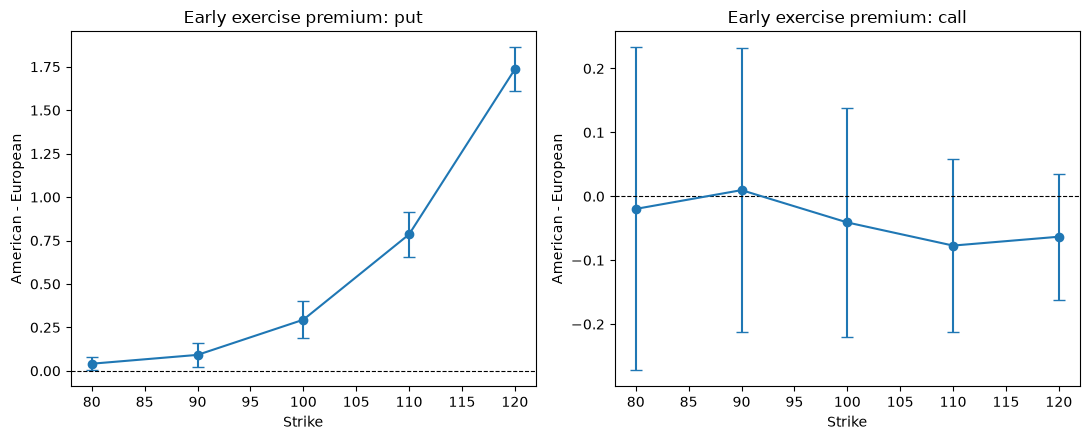

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

for a, opt in zip(ax, ["put", "call"]):
    d = df[df["option"] == opt]
    a.errorbar(d["strike"], d["premium"], yerr=1.96 * d["std_error"], fmt="o-", capsize=4)
    a.axhline(0, color="black", lw=0.8, linestyle="--")
    a.set_title(f"Early exercise premium: {opt}")
    a.set_xlabel("Strike")
    a.set_ylabel("American - European")

plt.tight_layout()
plt.savefig("../figures/premium_vs_strike.png", dpi=150)
plt.show()

In [8]:
import pandas as pd

sigmas = [0.10, 0.20, 0.30, 0.40, 0.50]
df_vol = pd.concat([compare_american_european(S0, [100], r, q, s, T, n_steps, n_paths, options=("put",)).assign(sigma=s) for s in sigmas], ignore_index=True)

print(df_vol[["sigma", "european", "american", "std_error", "premium", "premium_pct"]].round(4).to_string(index=False))

 sigma  european  american  std_error  premium  premium_pct
   0.1    2.5744    2.8711     0.0252   0.2967      11.5234
   0.2    6.3301    6.6242     0.0550   0.2941       4.6464
   0.3   10.1234   10.4379     0.0819   0.3145       3.1068
   0.4   13.9024   14.2533     0.1061   0.3509       2.5238
   0.5   17.6495   18.0306     0.1279   0.3811       2.1591


In [9]:
maturities = [0.25, 0.5, 1.0, 1.5, 2.0]
df_mat = pd.concat([compare_american_european(S0, [100], r, q, sigma, Tm, max(10, round(50 * Tm)), n_paths, options=("put",)).assign(T=Tm) for Tm in maturities], ignore_index=True)

print(df_mat[["T", "european", "american", "std_error", "premium", "premium_pct"]].round(4).to_string(index=False))

   T  european  american  std_error  premium  premium_pct
0.25    3.5924    3.6776     0.0331   0.0852       2.3725
0.50    4.8336    4.9673     0.0425   0.1337       2.7658
1.00    6.3301    6.6242     0.0550   0.2941       4.6464
1.50    7.2712    7.8066     0.0634   0.5354       7.3634
2.00    7.9266    8.6069     0.0672   0.6803       8.5827


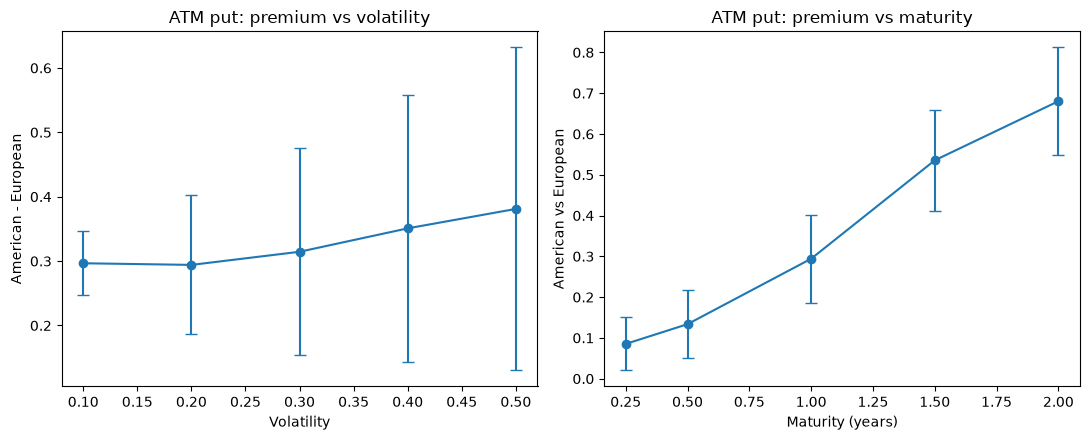

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].errorbar(df_vol["sigma"], df_vol["premium"], yerr = 1.96 * df_vol["std_error"], fmt="o-", capsize=4)
ax[0].set_title("ATM put: premium vs volatility")
ax[0].set_xlabel("Volatility")
ax[0].set_ylabel("American - European")

ax[1].errorbar(df_mat["T"], df_mat["premium"], yerr= 1.96 * df_mat["std_error"], fmt="o-", capsize=4)
ax[1].set_title("ATM put: premium vs maturity")
ax[1].set_xlabel("Maturity (years)")
ax[1].set_ylabel("American vs European")

plt.tight_layout()
plt.savefig("../figures/premium_vs_vol_and_maturity.png", dpi=150)
plt.show()

In [11]:
r2, q2 = 0.03, 0.08 # q > r: early exercise of the call can be optimal
df_div = compare_american_european(S0, [90, 100, 110], r2, q2, sigma, T, n_steps, n_paths, options=("call",))

print(df_div[["strike", "european", "american", "std_error", "premium", "premium_pct"]].round(4).to_string(index=False))

 strike  european  american  std_error  premium  premium_pct
     90    9.9123   11.3495     0.0617   1.4372      14.4995
    100    5.4088    5.9463     0.0579   0.5375       9.9373
    110    2.7036    2.9146     0.0436   0.2111       7.8073
